# Kenya maize farm risk score: regression models

**Mission.** My mission is to build Africa's capacity to make things, by starting and running technology companies on the continent. This project builds one piece of that: digital infrastructure for farm insurance.

**Problem.** Most smallholder maize farmers in Kenya farm uninsured, so one bad season can wipe them out and lock them out of credit.

**Use case.** The prediction is used by enrolment agents and underwriters at agricultural insurers in Kenya. When a farmer signs up, before planting, the model predicts the field's expected maize yield from what is known at that moment: the field's location and soil, and the inputs the farmer plans to use. The insurer turns the prediction into a low, medium or high risk band to decide cover and price.

**Target.** `yield_kg_ha`: maize grain yield in kilograms per hectare, a continuous number.

**Data.** Aramburu Merlos, F., Tenorio, F. A., Mashingaidze, N., Sananka, A., Aston, S., & Grassini, P. (2024). *Maize management and yield of smallholder farmers in Sub-Saharan Africa between 2016 and 2022* (Version 2) [Dataset]. Zenodo. https://doi.org/10.5281/zenodo.11122388 (CC BY 4.0). One Acre Fund staff measured each field's yield at harvest in two randomly placed 36 m² boxes, and the authors screened the yields for outliers with a Bonferroni outlier test.

In [1]:
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42
TARGET = "yield_kg_ha"

raw = pd.read_csv("One_Acre_Fund_MEL_maize_survey_data_2016-2022.csv")
print(f"{raw.shape[0]:,} rows, {raw.shape[1]} columns")
raw["country"].value_counts()

14,773 rows, 53 columns


country
kenya       7258
tanzania    3710
rwanda      2080
zambia       861
burundi      640
nigeria      115
uganda       109
Name: count, dtype: int64

## Focus on Kenya

Insurers price risk market by market, so the model covers one country. Kenya has the most fields in the survey, and all of them are from the main (long-rains) season, so every row describes the same kind of decision.

In [2]:
kenya = raw[raw["iso"] == "KEN"].reset_index(drop=True)
print(f"{kenya.shape[0]:,} rows, {kenya.shape[1]} columns")
print("Years:", sorted(kenya["year"].unique().tolist()))
print("Seasons:", list(kenya["season"].unique()))
kenya.head()

7,258 rows, 53 columns
Years: [2016, 2017, 2018, 2019, 2020]
Seasons: ['first season']


,year,country,iso,season,cz,lon,lat,strat,avg_season_gdd,avg_season_ai,avg_season_tavg,season_prec,season_prec_1,season_prec_2,season_prec_3,elev,twi,soil_rzpawhc,soil_clay,soil_pH,soil_orgC,soil_ECEC,plant_date,harvest_date,plant_date_dev,plant_doy,pl_m2,row_spacing,hybrid,hyb_type,hyb_mat,hyb_yor,hyb_tol_mln,hyb_tol_msv,hyb_tol_gls,hyb_tol_nclb,hyb_tol_rust,hyb_tol_ear_rot,N_kg_ha,P_kg_ha,K_kg_ha,compost,comp_kg_ha,manure,fert_in_hole,lime_kg_ha,weeding,pesticide,disease,pest,striga,water_excess,yield_kg_ha
0,2016,kenya,KEN,first season,7701,34.067,0.227,01_KEN7701S1,2509.099854,0.998492,21.275661,677.039708,228.759519,365.227443,83.052746,1280,8.322142,120.0,34.0,6.3,11.182494,13.879732,2016-04-13,NaN,22.0,104.0,NaN,70.666656,True,NaN,2.0,2004.0,False,False,False,False,False,False,51.892050,24.71050,0.0,False,0.0,NaN,True,0.0,NaN,NaN,False,False,NaN,False,1462.951369
1,2017,kenya,KEN,first season,7701,34.100,0.238,01_KEN7701S1,2552.900146,1.038017,21.507408,760.532583,154.624451,464.134379,141.773752,1288,10.117007,120.0,38.0,5.9,12.463738,12.463738,2017-03-31,2017-07-14,8.0,90.0,2.736283,68.666664,True,NaN,2.0,2004.0,False,False,False,False,False,False,51.892050,24.71050,0.0,False,0.0,NaN,True,0.0,False,True,False,True,NaN,False,2817.771269
2,2019,kenya,KEN,first season,7701,34.082,0.247,01_KEN7701S1,2580.099854,1.008526,21.651323,724.153837,181.676820,359.354439,183.122578,1243,7.909871,120.0,33.0,6.2,10.023176,10.023176,2019-04-15,2019-08-05,23.0,105.0,4.541739,72.666664,True,NaN,2.0,2004.0,False,False,False,False,False,False,27.873444,13.83788,0.0,False,0.0,NaN,True,0.0,False,False,False,True,NaN,False,0.000000
3,2020,kenya,KEN,first season,7701,34.098,0.232,01_KEN7701S1,2562.800049,1.018445,21.559790,998.342599,379.451999,428.776234,190.114366,1271,8.969049,120.0,32.0,6.0,10.023176,10.023176,2020-03-28,2020-07-16,6.0,88.0,3.986111,NaN,True,3_way_hyb,1.0,2003.0,False,False,True,False,False,True,44.478900,49.42100,0.0,True,NaN,True,False,0.0,True,False,False,True,True,False,4788.722787
4,2020,kenya,KEN,first season,7701,34.094,0.272,01_KEN7701S1,2612.800049,1.023641,21.824339,998.342599,379.451999,428.776234,190.114366,1226,6.008638,120.0,33.0,5.9,12.463738,11.182494,2020-02-05,2020-08-04,-46.0,36.0,2.277778,NaN,True,NaN,2.0,2004.0,False,False,False,False,False,False,51.892050,24.71050,0.0,False,NaN,NaN,False,0.0,False,NaN,False,False,True,False,2193.982268


In [3]:
features_all = kenya.drop(columns=TARGET)
numeric_columns = features_all.select_dtypes("number").columns
categorical_columns = features_all.columns.difference(numeric_columns)
print(f"{len(kenya):,} rows and {features_all.shape[1]} feature columns: "
      f"{len(numeric_columns)} numeric, {len(categorical_columns)} categorical (text or yes/no)")
print("Categorical columns:", list(categorical_columns))
kenya[TARGET].describe().round(1)

7,258 rows and 52 feature columns: 29 numeric, 23 categorical (text or yes/no)
Categorical columns: ['compost', 'country', 'disease', 'fert_in_hole', 'harvest_date', 'hyb_tol_ear_rot', 'hyb_tol_gls', 'hyb_tol_mln', 'hyb_tol_msv', 'hyb_tol_nclb', 'hyb_tol_rust', 'hyb_type', 'hybrid', 'iso', 'manure', 'pest', 'pesticide', 'plant_date', 'season', 'strat', 'striga', 'water_excess', 'weeding']


count    7258.0
mean     3019.7
std      1707.2
min         0.0
25%      1806.8
50%      2764.6
75%      3973.6
max      9903.5
Name: yield_kg_ha, dtype: float64

## Explore the data

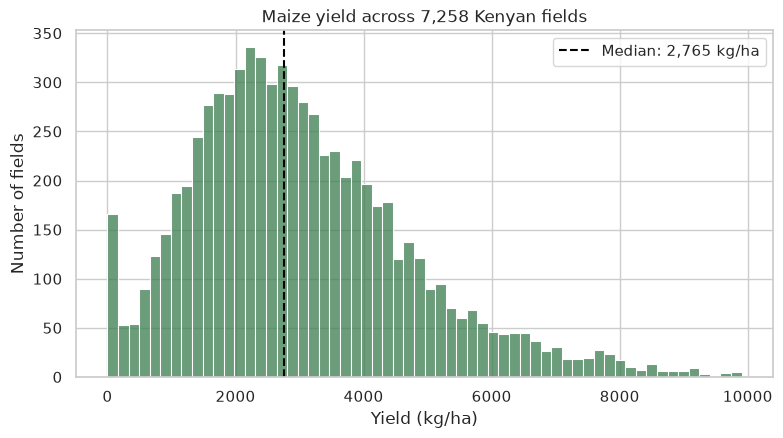

Fields with zero yield: 144
Fields under 1,000 kg/ha: 8.9%


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

median_yield = kenya[TARGET].median()
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(kenya[TARGET], bins=60, color="#3b7d4f", ax=ax)
ax.axvline(median_yield, color="black", linestyle="--", label=f"Median: {median_yield:,.0f} kg/ha")
ax.set(title=f"Maize yield across {len(kenya):,} Kenyan fields", xlabel="Yield (kg/ha)", ylabel="Number of fields")
ax.legend()
plt.show()

print(f"Fields with zero yield: {(kenya[TARGET] == 0).sum()}")
print(f"Fields under 1,000 kg/ha: {(kenya[TARGET] < 1000).mean():.1%}")

**What it shows.** Yield is skewed to the right: most fields harvest between 1,500 and 4,500 kg/ha (median 2,765), a long tail reaches almost 10,000 kg/ha, and 144 fields recorded zero. **What I decided.** I keep the zero-yield fields, because a crop failure is exactly the event an insurer has to price and the dataset's authors already screened the yields for statistical outliers. Because MSE squares errors, these extremes weigh heavily in the loss, so I also report RMSE in kg/ha to keep the errors readable.

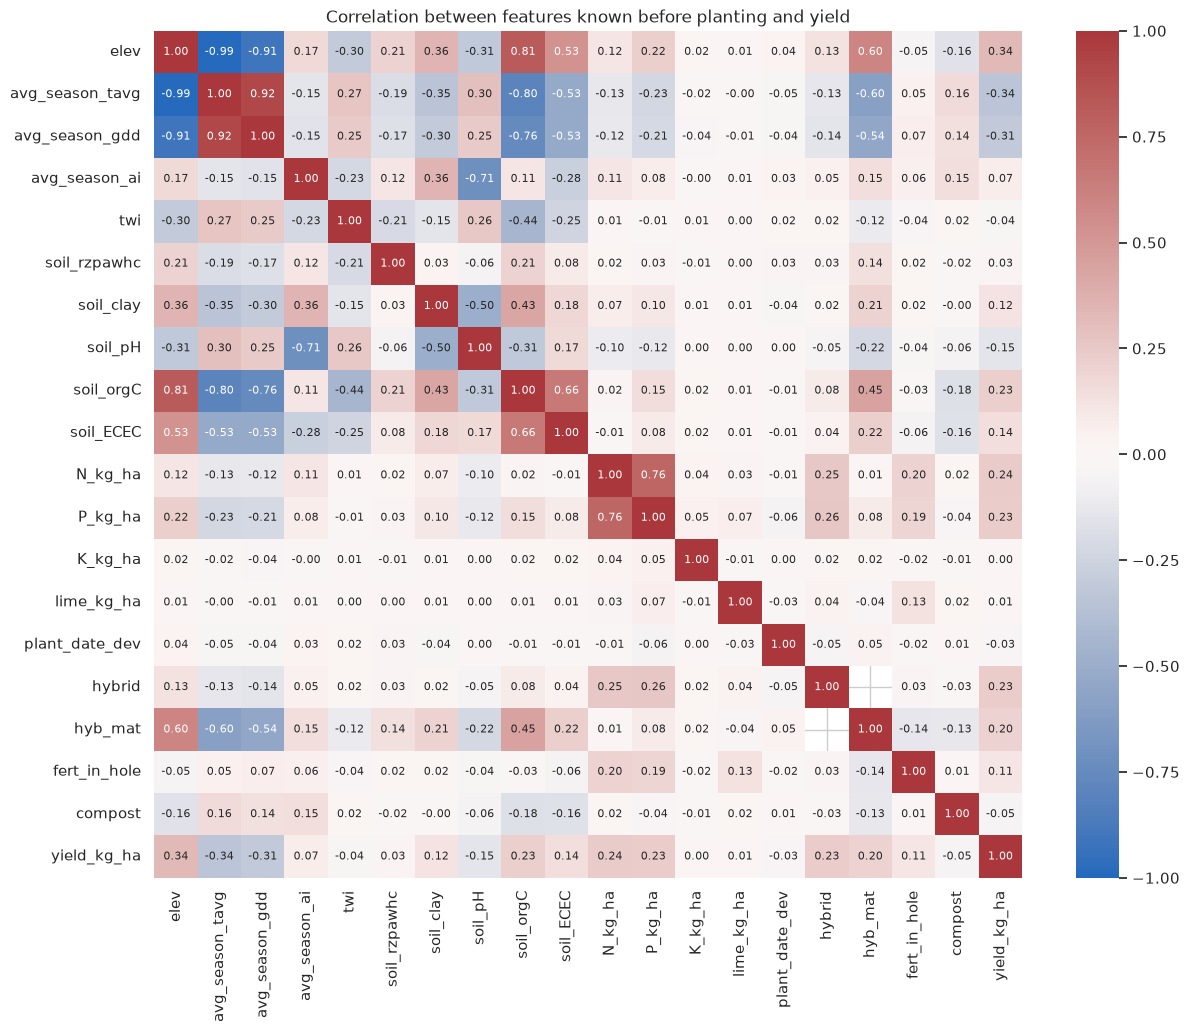

In [5]:
pre_planting = [
    "elev", "avg_season_tavg", "avg_season_gdd", "avg_season_ai", "twi", "soil_rzpawhc",
    "soil_clay", "soil_pH", "soil_orgC", "soil_ECEC", "N_kg_ha", "P_kg_ha", "K_kg_ha",
    "lime_kg_ha", "plant_date_dev", "hybrid", "hyb_mat", "fert_in_hole", "compost",
]
eda = kenya[pre_planting + [TARGET]].astype(float)

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(eda.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation between features known before planting and yield")
plt.show()

**What it shows.** Elevation, average season temperature and growing degree days are almost the same measurement (r = −0.99 and −0.91 with elevation), and yield's strongest links are only moderate: elevation +0.34, nitrogen +0.24, and phosphorus, hybrid seed and soil organic carbon +0.23 each. **What I decided.** I keep only elevation from that trio, because an agent can read it from a phone's GPS, and because no link is strong I also test non-linear models. Nitrogen and phosphorus overlap (0.76), so I test later whether both are needed (the blank hybrid and maturity cells appear because maturity is only recorded for hybrids).

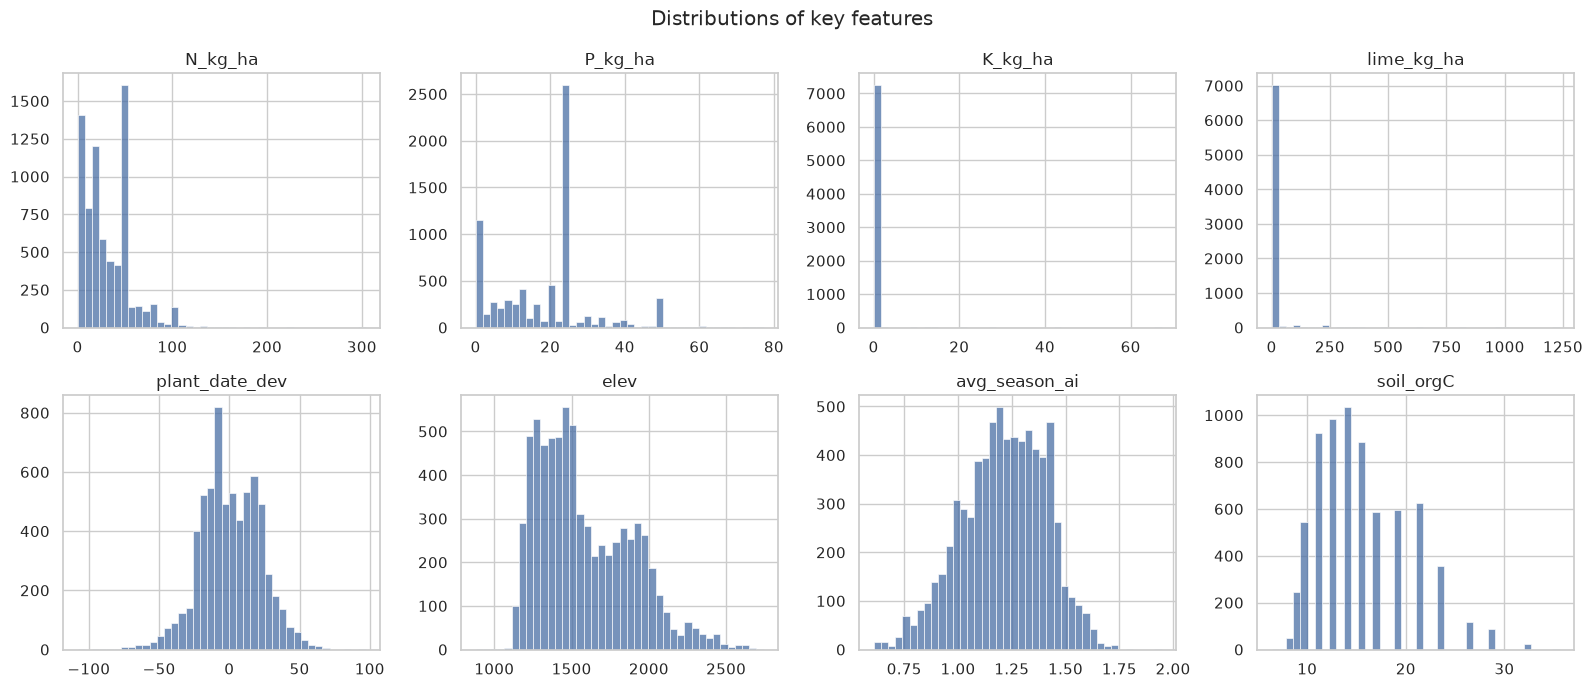

N_kg_ha: zero in 10.9% of fields
P_kg_ha: zero in 15.4% of fields
K_kg_ha: zero in 99.7% of fields
lime_kg_ha: zero in 96.1% of fields


In [6]:
to_plot = ["N_kg_ha", "P_kg_ha", "K_kg_ha", "lime_kg_ha", "plant_date_dev", "elev", "avg_season_ai", "soil_orgC"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, column in zip(axes.flat, to_plot):
    sns.histplot(kenya[column].dropna(), bins=40, color="#4a6fa5", ax=ax)
    ax.set(title=column, xlabel="", ylabel="")
fig.suptitle("Distributions of key features")
plt.tight_layout()
plt.show()

for column in ["N_kg_ha", "P_kg_ha", "K_kg_ha", "lime_kg_ha"]:
    print(f"{column}: zero in {(kenya[column] == 0).mean():.1%} of fields")

**What it shows.** Potassium is zero on 99.7% of fields and lime on 96.1%, while nitrogen and phosphorus pile up at zero and at about 50 and 25 kg/ha, which suggests many farmers apply the same standard rate. Planting dates centre on the local average, mostly within about three weeks of it, and elevation runs from about 900 to 2,700 m. **What I decided.** I drop potassium and lime because they carry almost no information, and I use these observed ranges to set the input limits in the API.

## Feature engineering: columns we drop and why

The model may only use what an insurer knows when the farmer enrols, before planting. Each dropped column falls into one of these groups. The evidence for each group is printed below.

| Group | Columns | Why |
|---|---|---|
| Only known once the season is under way | `season_prec`, `season_prec_1`, `season_prec_2`, `season_prec_3`, `harvest_date`, `pl_m2`, `row_spacing`, `weeding`, `pesticide`, `disease`, `pest`, `striga`, `water_excess` | Rainfall during the season, plant counts and crop damage are measured after enrolment. Using them would let the model see the future. |
| Identifiers, single values or raw forms | `country`, `iso`, `season`, `strat`, `year`, `cz`, `lat`, `lon`, `plant_date`, `plant_doy` | Country, ISO code and season have one value in Kenya. `strat` is a survey label. `year` only covers 2016 to 2020, so future enrolment years fall outside it. An agent cannot know the climate-zone code `cz`, and raw coordinates are not something an agent types; elevation, aridity and the soil values carry the location's effect. Calendar planting dates are tied to one year, so `plant_date_dev` (days earlier or later than the local average) replaces them. |
| Mostly empty | `manure`, `hyb_type`, `hyb_yor`, `hyb_tol_mln`, `hyb_tol_msv`, `hyb_tol_gls`, `hyb_tol_nclb`, `hyb_tol_rust`, `hyb_tol_ear_rot`, `comp_kg_ha` | More than 25% missing. |
| Almost always zero | `K_kg_ha`, `lime_kg_ha` | No variation means no information. |
| Duplicates of elevation | `avg_season_tavg`, `avg_season_gdd` | The heatmap shows correlations of −0.99 and −0.91 with elevation. Elevation stays because an agent can read it from a phone's GPS. |
| Combined into `seed_type` | `hybrid`, `hyb_mat` | Replaced by one categorical feature, built below. |

In [7]:
DROPPED = {
    "only known once the season is under way": [
        "season_prec", "season_prec_1", "season_prec_2", "season_prec_3", "harvest_date", "pl_m2",
        "row_spacing", "weeding", "pesticide", "disease", "pest", "striga", "water_excess"],
    "identifiers, single values or raw forms": [
        "country", "iso", "season", "strat", "year", "cz", "lat", "lon", "plant_date", "plant_doy"],
    "mostly empty": [
        "manure", "hyb_type", "hyb_yor", "hyb_tol_mln", "hyb_tol_msv", "hyb_tol_gls",
        "hyb_tol_nclb", "hyb_tol_rust", "hyb_tol_ear_rot", "comp_kg_ha"],
    "almost always zero": ["K_kg_ha", "lime_kg_ha"],
    "duplicates of elevation": ["avg_season_tavg", "avg_season_gdd"],
    "combined into seed_type": ["hybrid", "hyb_mat"],
}
KEPT = ["elev", "avg_season_ai", "twi", "soil_rzpawhc", "soil_clay", "soil_pH", "soil_orgC",
        "soil_ECEC", "N_kg_ha", "P_kg_ha", "plant_date_dev", "fert_in_hole", "compost"]

dropped_columns = [column for group in DROPPED.values() for column in group]
assert sorted(dropped_columns + KEPT + [TARGET]) == sorted(kenya.columns), "every column must be kept or dropped"

evidence = pd.DataFrame({
    "group": {column: group for group, columns in DROPPED.items() for column in columns},
    "missing %": kenya[dropped_columns].isna().mean().mul(100).round(1),
    "distinct values": kenya[dropped_columns].nunique(),
})
in_season_numeric = ["season_prec", "season_prec_1", "season_prec_2", "season_prec_3", "pl_m2"]
evidence["corr with yield"] = kenya[in_season_numeric].corrwith(kenya[TARGET]).round(2)
evidence

,group,missing %,distinct values,corr with yield
season_prec,only known once the season is under way,0.0,2331,0.18
season_prec_1,only known once the season is under way,0.0,2321,0.06
season_prec_2,only known once the season is under way,0.0,2281,0.05
season_prec_3,only known once the season is under way,0.0,2296,0.27
harvest_date,only known once the season is under way,20.8,648,NaN
pl_m2,only known once the season is under way,32.8,2978,0.30
row_spacing,only known once the season is under way,56.1,359,NaN
weeding,only known once the season is under way,15.7,2,NaN
pesticide,only known once the season is under way,51.3,2,NaN
disease,only known once the season is under way,0.0,2,NaN


The in-season columns do relate to yield (whole-season rainfall has r = 0.18), but none of them exist when the farmer enrols, so keeping them would make the model look better on paper than it can be in use. After these drops, 13 candidate features remain, and `seed_type` is built next.

### Engineer `seed_type`

`hybrid` says whether the farmer planted a commercial hybrid, and `hyb_mat` gives the hybrid's maturity on a 0.5 to 3 scale. The dataset describes maturity as early, medium or late, so whole numbers 1, 2 and 3 map to those classes. The half-steps are not defined, so the yields decide where they go.

In [8]:
hybrids = kenya[kenya["hybrid"] == True]
hybrids.groupby("hyb_mat", dropna=False)[TARGET].agg(["count", "median"]).round(0)

,count,median
hyb_mat,,
0.5,13,1555.0
1.0,1155,2735.0
1.5,134,2809.0
2.0,834,2652.0
2.5,849,2792.0
3.0,2442,3492.0
NaN,945,2228.0


Maturity 3 (late) clearly stands apart, at a median of 3,492 kg/ha. The half-steps 1.5 and 2.5 yield like early and medium hybrids (2,809 and 2,792 kg/ha), not like late ones, so each half-step joins the class below it, and the 13 fields at 0.5 join the early class.

In [9]:
SEED_TYPES = ["local_or_opv", "hybrid_early", "hybrid_medium", "hybrid_late", "hybrid_unknown_maturity"]


def seed_type(is_hybrid, maturity):
    if not is_hybrid:
        return "local_or_opv"
    if pd.isna(maturity):
        return "hybrid_unknown_maturity"
    if maturity <= 1.5:
        return "hybrid_early"
    if maturity <= 2.5:
        return "hybrid_medium"
    return "hybrid_late"


data = kenya[KEPT + [TARGET]].copy()
data["seed_type"] = [seed_type(h, m) for h, m in zip(kenya["hybrid"], kenya["hyb_mat"])]
CANDIDATES = KEPT + ["seed_type"]

data.groupby("seed_type")[TARGET].agg(["count", "median"]).reindex(SEED_TYPES).round(0)

,count,median
seed_type,,
local_or_opv,886,1781.0
hybrid_early,1302,2736.0
hybrid_medium,1683,2703.0
hybrid_late,2442,3492.0
hybrid_unknown_maturity,945,2228.0


Seed type matters: late-maturing hybrids yield a median of 3,492 kg/ha, about double the 1,781 kg/ha from local or open-pollinated seed. Hybrids whose maturity was not recorded sit in between, so they keep their own category instead of being guessed.